# 01 - Regression: predicting house prices

A from-scratch regression workflow on a **synthetic housing market** (so the true relationships are known and we can check what each model recovers): linear regression (closed form *and* gradient descent), polynomial features, Ridge / Lasso / Elastic Net, gradient boosting, and honest model selection with cross-validation.

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
import mlforge
from mlforge import visualization as viz
print("MLForge", mlforge.__version__)

MLForge 0.2.0


## 1. Data
Price depends linearly on size, bedrooms and age, non-linearly on location (distance to centre), and has noise. Two columns are pure noise.

In [2]:
rng = np.random.RandomState(42)
n = 600
size = rng.uniform(40, 250, n)            # m^2
bedrooms = rng.randint(1, 6, n).astype(float)
age = rng.uniform(0, 60, n)
dist = rng.uniform(0.5, 30, n)            # km to centre
noise1, noise2 = rng.randn(n), rng.randn(n)
price = (1800*size + 12000*bedrooms - 900*age + 150000*np.exp(-dist/6) + rng.randn(n)*15000)/1000   # k$
names = ["size", "bedrooms", "age", "dist", "noise1", "noise2"]
X = np.column_stack([size, bedrooms, age, dist, noise1, noise2])
print(X.shape, "price range (k$):", price.min().round(), "-", price.max().round())

(600, 6) price range (k$): 59.0 - 579.0


In [3]:
from mlforge.preprocessing import train_test_split, StandardScaler
Xtr, Xte, ytr, yte = train_test_split(X, price, test_size=0.25, random_state=0)
sc = StandardScaler().fit(Xtr)                       # fit on TRAIN only (no leakage)
Ztr, Zte = sc.transform(Xtr), sc.transform(Xte)

## 2. Linear regression two ways
The closed-form solution and gradient descent minimise the same loss, so on standardised features they must agree. (Plain GD converges geometrically here; *Adam* moves each parameter by about `learning_rate` per step, so it would need thousands of steps just to reach an intercept of ~300 - a good reminder to match the optimizer to the scale of the problem.)

closed form  R2 = 0.9532  RMSE = 24.4
grad descent R2 = 0.9532
max |coef difference|: 0.0


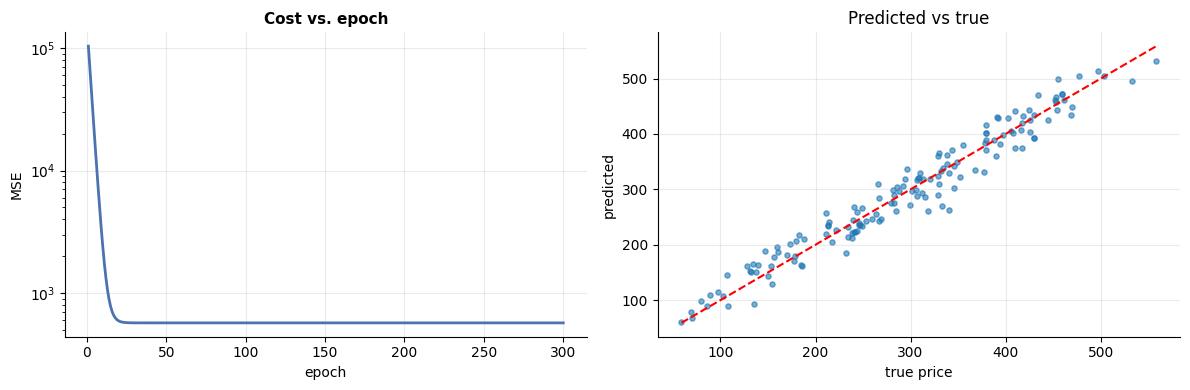

In [4]:
from mlforge.linear_model import LinearRegression
from mlforge.metrics import r2_score, root_mean_squared_error
exact = LinearRegression().fit(Ztr, ytr)
gd = LinearRegression(solver="gd", learning_rate=0.1, n_iters=300).fit(Ztr, ytr)
print("closed form  R2 =", round(exact.score(Zte, yte), 4), " RMSE =", round(root_mean_squared_error(yte, exact.predict(Zte)), 2))
print("grad descent R2 =", round(gd.score(Zte, yte), 4))
print("max |coef difference|:", np.abs(exact.coef_ - gd.coef_).max().round(5))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
viz.plot_learning_curve(gd.cost_history_, ax=ax[0], log_y=True, ylabel="MSE")
ax[1].scatter(yte, exact.predict(Zte), s=14, alpha=.6); ax[1].plot([yte.min(), yte.max()], [yte.min(), yte.max()], "r--")
ax[1].set_xlabel("true price"); ax[1].set_ylabel("predicted"); ax[1].set_title("Predicted vs true")
plt.tight_layout()

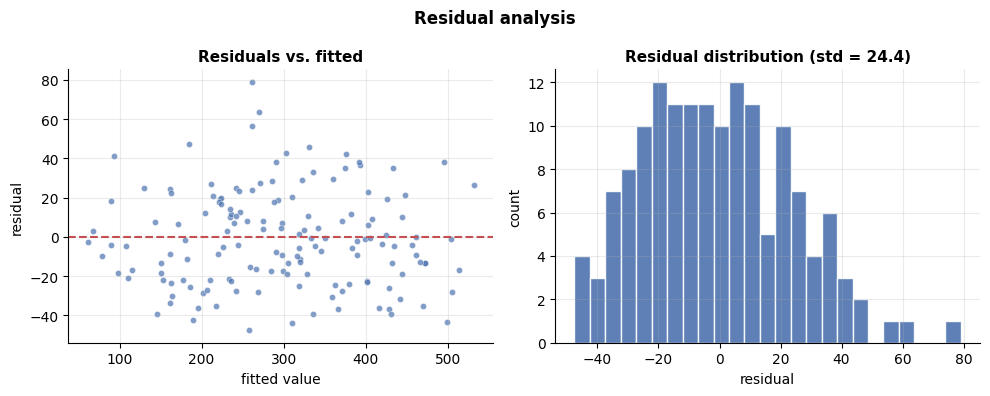

In [5]:
_ = viz.plot_residuals(yte, exact.predict(Zte))

## 3. Regularisation and feature selection
Lasso should zero out the two noise columns. The path plot shows coefficients shrinking as alpha grows.

In [6]:
from mlforge.linear_model import Ridge, Lasso, ElasticNet
for name, m in [("OLS", exact), ("Ridge(10)", Ridge(alpha=10).fit(Ztr, ytr)), ("Lasso(1)", Lasso(alpha=1.0).fit(Ztr, ytr)),
                ("ElasticNet", ElasticNet(alpha=0.3, l1_ratio=.5).fit(Ztr, ytr))]:
    print(f"{name:<11} R2={m.score(Zte, yte):.4f}  coefs:", {n: round(float(c), 1) for n, c in zip(names, m.coef_)})

OLS         R2=0.9532  coefs: {'size': 112.5, 'bedrooms': 18.0, 'age': -17.3, 'dist': -30.1, 'noise1': -0.2, 'noise2': 0.3}
Ridge(10)   R2=0.9530  coefs: {'size': 110.0, 'bedrooms': 17.4, 'age': -17.1, 'dist': -29.4, 'noise1': -0.3, 'noise2': 0.3}
Lasso(1)    R2=0.9527  coefs: {'size': 111.5, 'bedrooms': 16.9, 'age': -16.4, 'dist': -29.1, 'noise1': 0.0, 'noise2': 0.0}
ElasticNet  R2=0.9376  coefs: {'size': 97.5, 'bedrooms': 14.8, 'age': -15.5, 'dist': -25.9, 'noise1': -0.9, 'noise2': 0.0}


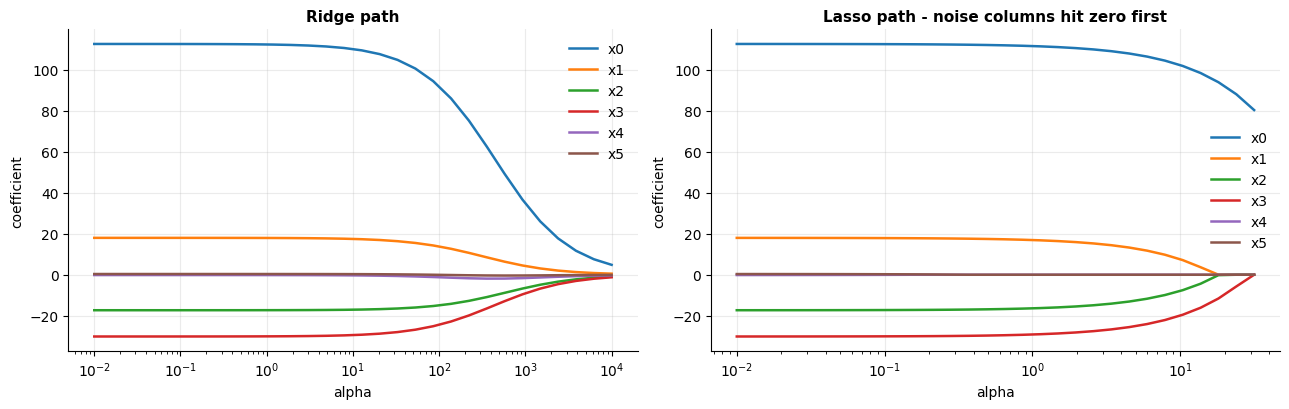

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
viz.plot_regularization_path(lambda a: Ridge(alpha=a), Ztr, ytr, np.logspace(-2, 4, 30), ax=ax[0], title="Ridge path")
viz.plot_regularization_path(lambda a: Lasso(alpha=a), Ztr, ytr, np.logspace(-2, 1.5, 30), ax=ax[1], title="Lasso path - noise columns hit zero first")
plt.tight_layout()

## 4. Non-linearity: polynomial features and boosting
Price depends on `exp(-dist/6)`, which a straight line cannot capture.

In [8]:
from mlforge.linear_model import PolynomialRegression
from mlforge.tree import GradientBoostingRegressor, RandomForestRegressor
results = {}
for name, m in {"Linear": LinearRegression(), "Polynomial(3)": PolynomialRegression(degree=3),
                "RandomForest": RandomForestRegressor(60, max_depth=8, oob_score=True, random_state=0),
                "GradientBoosting": GradientBoostingRegressor(200, learning_rate=0.05, max_depth=3, subsample=.8, random_state=0)}.items():
    m.fit(Ztr, ytr); results[name] = m.score(Zte, yte)
for k, v in results.items(): print(f"{k:<18} test R2 = {v:.4f}")

Linear             test R2 = 0.9532
Polynomial(3)      test R2 = 0.9759
RandomForest       test R2 = 0.9526
GradientBoosting   test R2 = 0.9707


## 5. Honest model selection
Grid search with 5-fold cross-validation in a `Pipeline` (so scaling is re-fitted inside every fold). With 450 training rows and only 6 features, regularisation has little to fix, so cross-validation should - and does - pick one of the *smallest* alphas: a model-selection procedure that can say "no regularisation needed" is working correctly.

In [9]:
from mlforge import Pipeline
from mlforge.model_selection import GridSearchCV
pipe = Pipeline([("scale", StandardScaler()), ("model", Ridge())])
gs = GridSearchCV(pipe, {"model__alpha": [0.01, 0.1, 1, 10, 100, 1000]}, cv=5, scoring="neg_root_mean_squared_error").fit(Xtr, ytr)
print("best:", gs.best_params_, " CV RMSE =", round(-gs.best_score_, 2), " test R2 =", round(r2_score(yte, gs.predict(Xte)), 4))

best: {'model__alpha': 0.01}  CV RMSE = 24.4  test R2 = 0.9532


<Axes: title={'center': 'Learning curve (R2)'}, xlabel='training set size', ylabel='score'>

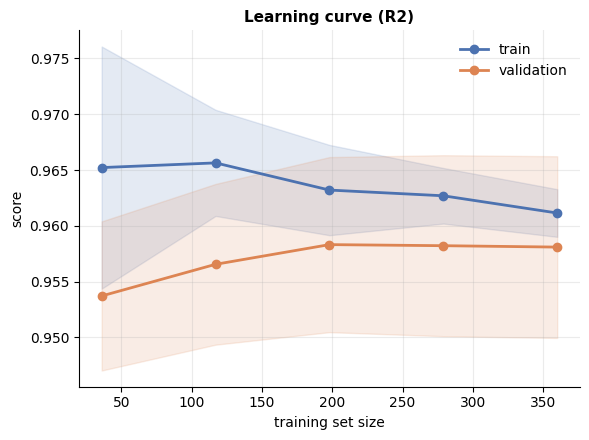

In [10]:
from mlforge.model_selection import learning_curve
sizes, tr, va = learning_curve(Ridge(alpha=1), Ztr, ytr, cv=5, scoring="r2")
viz.plot_model_selection_curve(sizes, tr, va, title="Learning curve (R2)")

## Takeaways
* Closed form and gradient descent reach the same solution; GD needs scaled features.
* Lasso identifies irrelevant features; Ridge shrinks without zeroing.
* A linear model plateaus on non-linear structure; trees / boosting capture it.
* Put preprocessing inside the `Pipeline` so cross-validation is leak-free.